# Image Classification: SVM + HOG trên MNIST

**Phương pháp:**
- **Feature Extraction:** HOG (Histogram of Oriented Gradients)
- **Classifier:** SVM (Support Vector Machine)
- **Dataset:** MNIST (70,000 ảnh chữ số viết tay 28x28)

---

### Pipeline tổng quan:
```
Raw Image (28x28) → HOG Features → SVM Classifier → Prediction
```

## 1. Import thư viện

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

# Dataset
from sklearn.datasets import fetch_openml

# Feature Extraction - HOG
from skimage.feature import hog
from skimage import exposure

# SVM Classifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

## 2. Load Dataset MNIST

In [4]:
print('📥 Đang tải MNIST dataset...')
start = time.time()

# Load MNIST từ sklearn (tự động download lần đầu)
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X, y = mnist.data, mnist.target.astype(int)

print(f'Tải xong! Thời gian: {time.time()-start:.2f}s')
print(f'Kích thước dataset: {X.shape}')
print(f'Số lớp: {len(np.unique(y))} (chữ số 0-9)')
print(f'Kiểu dữ liệu: {X.dtype}')

📥 Đang tải MNIST dataset...
Tải xong! Thời gian: 34.43s
Kích thước dataset: (70000, 784)
Số lớp: 10 (chữ số 0-9)
Kiểu dữ liệu: int64


## 3. Khám phá dữ liệu (EDA)

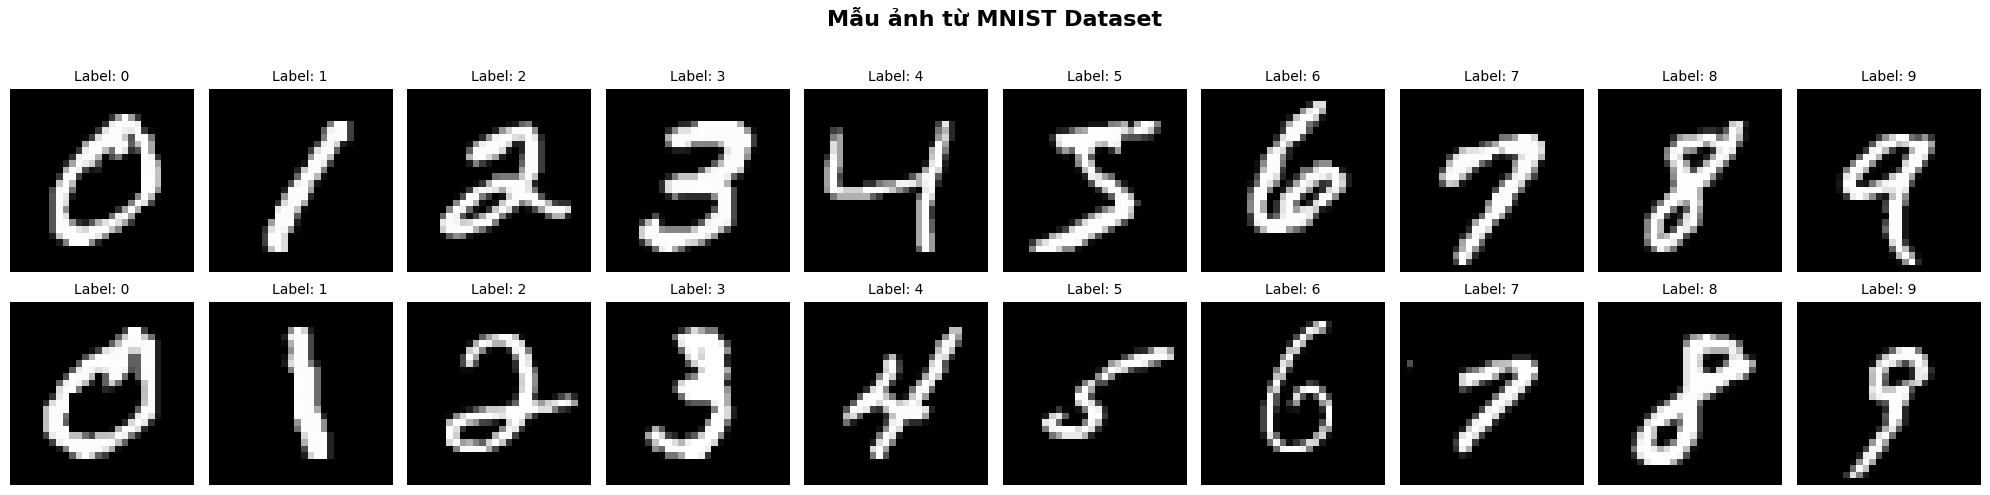

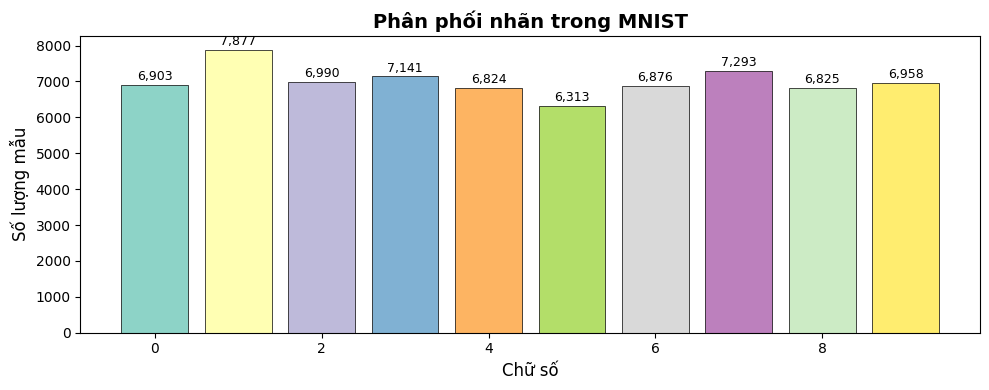

In [5]:
# Hiển thị một số mẫu từ dataset
fig, axes = plt.subplots(2, 10, figsize=(20, 5))
fig.suptitle('Mẫu ảnh từ MNIST Dataset', fontsize=16, fontweight='bold', y=1.02)

for digit in range(10):
    # Lấy mẫu đầu tiên của mỗi chữ số
    idx = np.where(y == digit)[0][0]
    img = X[idx].reshape(28, 28)
    
    axes[0, digit].imshow(img, cmap='gray')
    axes[0, digit].set_title(f'Label: {digit}', fontsize=10)
    axes[0, digit].axis('off')
    
    # Lấy mẫu thứ 2
    idx2 = np.where(y == digit)[0][1]
    img2 = X[idx2].reshape(28, 28)
    axes[1, digit].imshow(img2, cmap='gray')
    axes[1, digit].set_title(f'Label: {digit}', fontsize=10)
    axes[1, digit].axis('off')

plt.tight_layout()
plt.show()

# Phân phối nhãn
fig, ax = plt.subplots(figsize=(10, 4))
unique, counts = np.unique(y, return_counts=True)
bars = ax.bar(unique, counts, color=plt.cm.Set3(np.linspace(0, 1, 10)), edgecolor='black', linewidth=0.5)
ax.set_xlabel('Chữ số', fontsize=12)
ax.set_ylabel('Số lượng mẫu', fontsize=12)
ax.set_title('Phân phối nhãn trong MNIST', fontsize=14, fontweight='bold')
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 50,
            f'{count:,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 4. Tiền xử lý - HOG Feature Extraction

**HOG (Histogram of Oriented Gradients)** mô tả phân phối của các gradient cục bộ trong ảnh.

**Tham số HOG:**
- `orientations`: Số hướng gradient (8)
- `pixels_per_cell`: Kích thước cell (4x4)
- `cells_per_block`: Số cell trong mỗi block (2x2)
- `block_norm`: Phương pháp chuẩn hóa ('L2-Hys')

In [7]:
# Minh họa HOG Feature Extraction
sample_idx = np.where(y == 5)[0][0]
sample_img = X[sample_idx].reshape(28, 28)

# Tính HOG
hog_features, hog_image = hog(
    sample_img,
    orientations=8,
    pixels_per_cell=(4, 4),
    cells_per_block=(2, 2),
    block_norm='L2-Hys',
    visualize=True
)

# Tăng contrast để dễ nhìn
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))
hog_image_rescaled

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

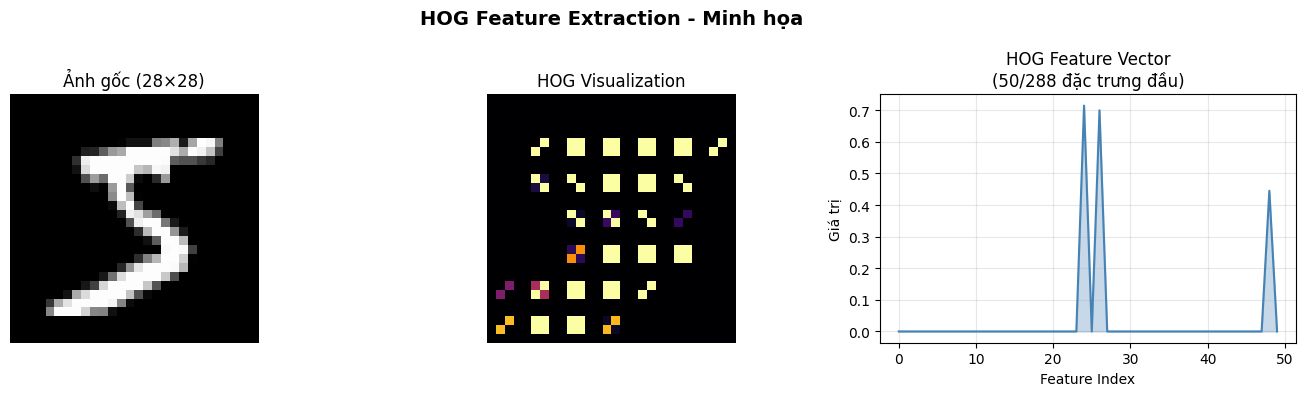

 Kích thước HOG feature vector: 1152 đặc trưng
   (So với 784 pixel gốc → Giảm chiều đáng kể!)


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('HOG Feature Extraction - Minh họa', fontsize=14, fontweight='bold')

axes[0].imshow(sample_img, cmap='gray')
axes[0].set_title('Ảnh gốc (28×28)', fontsize=12)
axes[0].axis('off')

axes[1].imshow(hog_image_rescaled, cmap='inferno')
axes[1].set_title('HOG Visualization', fontsize=12)
axes[1].axis('off')

axes[2].plot(hog_features[:50], color='steelblue', linewidth=1.5)
axes[2].fill_between(range(50), hog_features[:50], alpha=0.3, color='steelblue')
axes[2].set_title(f'HOG Feature Vector\n(50/288 đặc trưng đầu)', fontsize=12)
axes[2].set_xlabel('Feature Index')
axes[2].set_ylabel('Giá trị')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f' Kích thước HOG feature vector: {hog_features.shape[0]} đặc trưng')
print(f'   (So với 784 pixel gốc → Giảm chiều đáng kể!)')

In [9]:
# Hàm trích xuất HOG cho toàn bộ dataset
def extract_hog_features(X_data, orientations=8, pixels_per_cell=(4,4), cells_per_block=(2,2)):
    """
    Trích xuất đặc trưng HOG cho tập dữ liệu.
    
    Parameters:
    -----------
    X_data: np.array, shape (n_samples, 784)
    
    Returns:
    --------
    features: np.array, shape (n_samples, n_hog_features)
    """
    features = []
    for i, img_flat in enumerate(X_data):
        img = img_flat.reshape(28, 28)
        feat = hog(
            img,
            orientations=orientations,
            pixels_per_cell=pixels_per_cell,
            cells_per_block=cells_per_block,
            block_norm='L2-Hys'
        )
        features.append(feat)
        
        if (i+1) % 10000 == 0:
            print(f'  Đã xử lý: {i+1}/{len(X_data)} ảnh')
    
    return np.array(features)

## 5. Chia tập Train/Test

In [10]:
# MNIST chuẩn: 60,000 train, 10,000 test
X_train_raw, X_test_raw = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

# Chuẩn hóa pixel về [0, 1]
X_train_raw = X_train_raw / 255.0
X_test_raw  = X_test_raw  / 255.0

print(f'Tập Train: {X_train_raw.shape[0]:,} mẫu')
print(f'Tập Test : {X_test_raw.shape[0]:,} mẫu')

Tập Train: 60,000 mẫu
Tập Test : 10,000 mẫu


In [11]:
# Trích xuất HOG features
print('Đang trích xuất HOG features cho tập TRAIN...')
t0 = time.time()
X_train_hog = extract_hog_features(X_train_raw)
print(f'Train HOG xong! Thời gian: {time.time()-t0:.1f}s')

print('\nĐang trích xuất HOG features cho tập TEST...')
t0 = time.time()
X_test_hog = extract_hog_features(X_test_raw)
print(f'Test HOG xong! Thời gian: {time.time()-t0:.1f}s')

print(f'\n Kích thước feature sau HOG:')
print(f'   Train: {X_train_hog.shape}')
print(f'   Test : {X_test_hog.shape}')

Đang trích xuất HOG features cho tập TRAIN...
  Đã xử lý: 10000/60000 ảnh
  Đã xử lý: 20000/60000 ảnh
  Đã xử lý: 30000/60000 ảnh
  Đã xử lý: 40000/60000 ảnh
  Đã xử lý: 50000/60000 ảnh
  Đã xử lý: 60000/60000 ảnh
Train HOG xong! Thời gian: 23.9s

Đang trích xuất HOG features cho tập TEST...
  Đã xử lý: 10000/10000 ảnh
Test HOG xong! Thời gian: 3.6s

 Kích thước feature sau HOG:
   Train: (60000, 1152)
   Test : (10000, 1152)


## 6. Xây dựng và Huấn luyện mô hình SVM

In [12]:
# Xây dựng Pipeline: StandardScaler → SVM
print('Xây dựng Pipeline: StandardScaler + SVM (RBF kernel)...')

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',      # Radial Basis Function kernel
        C=10,              # Regularization parameter
        gamma='scale',     # Kernel coefficient
        decision_function_shape='ovr',  # One-vs-Rest
        random_state=42
    ))
])

print('Pipeline đã được tạo!')
print('\nCấu trúc Pipeline:')
print(svm_pipeline)

Xây dựng Pipeline: StandardScaler + SVM (RBF kernel)...
Pipeline đã được tạo!

Cấu trúc Pipeline:
Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', SVC(C=10, random_state=42))])


In [13]:
# Huấn luyện mô hình
print('🚀 Bắt đầu huấn luyện SVM + HOG...')
print('   (Quá trình này có thể mất vài phút tùy cấu hình máy)')

t_start = time.time()
svm_pipeline.fit(X_train_hog, y_train)
train_time = time.time() - t_start

print(f'Huấn luyện xong!')
print(f'Thời gian huấn luyện: {train_time:.2f}s ({train_time/60:.1f} phút)')

🚀 Bắt đầu huấn luyện SVM + HOG...
   (Quá trình này có thể mất vài phút tùy cấu hình máy)
Huấn luyện xong!
Thời gian huấn luyện: 331.25s (5.5 phút)


## 7. Đánh giá mô hình

In [14]:
# Dự đoán
print('Đang dự đoán trên tập Test...')
t0 = time.time()
y_pred = svm_pipeline.predict(X_test_hog)
pred_time = time.time() - t0

# Tính các chỉ số
accuracy = accuracy_score(y_test, y_pred)

print(f'\n{'='*50}')
print(f'KẾT QUẢ ĐÁNH GIÁ - SVM + HOG')
print(f'{'='*50}')
print(f'Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'Thời gian dự đoán: {pred_time:.2f}s')
print(f'Tốc độ: {len(X_test_hog)/pred_time:.0f} ảnh/giây')
print()
print('Classification Report:')
print(classification_report(y_test, y_pred, 
                           target_names=[str(i) for i in range(10)]))

Đang dự đoán trên tập Test...

KẾT QUẢ ĐÁNH GIÁ - SVM + HOG
Accuracy: 0.9828 (98.28%)
Thời gian dự đoán: 95.58s
Tốc độ: 105 ảnh/giây

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.99      0.98      1032
           3       0.97      0.99      0.98      1010
           4       0.99      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.99      0.98      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



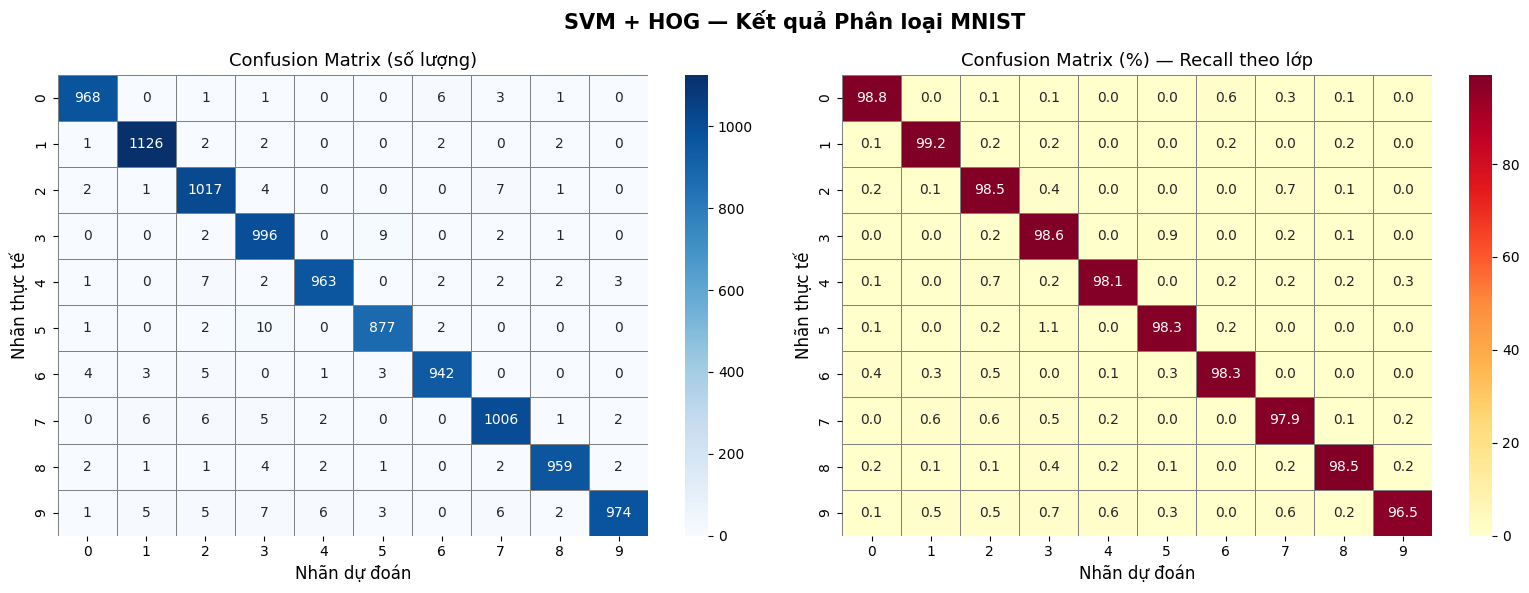

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('SVM + HOG — Kết quả Phân loại MNIST', fontsize=15, fontweight='bold')

# Heatmap số lượng
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10), ax=axes[0],
            linewidths=0.5, linecolor='gray')
axes[0].set_xlabel('Nhãn dự đoán', fontsize=12)
axes[0].set_ylabel('Nhãn thực tế', fontsize=12)
axes[0].set_title('Confusion Matrix (số lượng)', fontsize=13)

# Heatmap tỉ lệ
cm_pct = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis] * 100
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='YlOrRd',
            xticklabels=range(10), yticklabels=range(10), ax=axes[1],
            linewidths=0.5, linecolor='gray')
axes[1].set_xlabel('Nhãn dự đoán', fontsize=12)
axes[1].set_ylabel('Nhãn thực tế', fontsize=12)
axes[1].set_title('Confusion Matrix (%) — Recall theo lớp', fontsize=13)

plt.tight_layout()
plt.show()

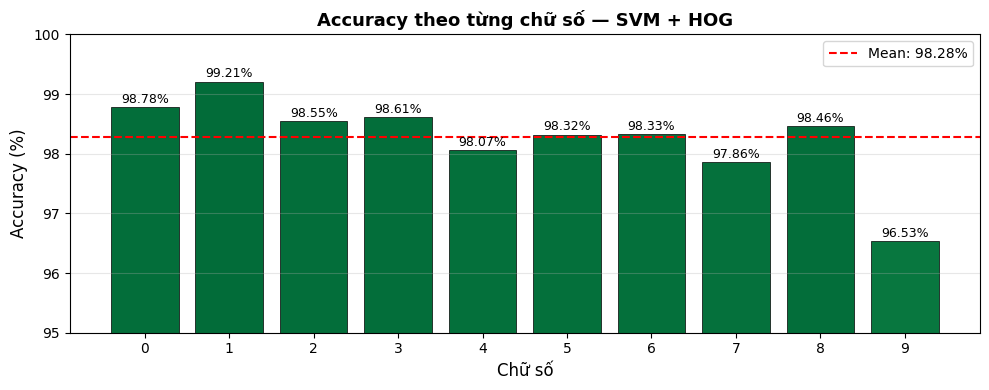

In [16]:
# Per-class accuracy
per_class_acc = cm.diagonal() / cm.sum(axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(range(10), per_class_acc * 100,
              color=plt.cm.RdYlGn(per_class_acc), edgecolor='black', linewidth=0.5)
ax.set_xlabel('Chữ số', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Accuracy theo từng chữ số — SVM + HOG', fontsize=13, fontweight='bold')
ax.set_xticks(range(10))
ax.set_ylim([95, 100])
for i, (bar, acc) in enumerate(zip(bars, per_class_acc)):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
            f'{acc*100:.2f}%', ha='center', va='bottom', fontsize=9)
ax.axhline(y=accuracy*100, color='red', linestyle='--', label=f'Mean: {accuracy*100:.2f}%')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Hiển thị các mẫu phân loại sai
wrong_mask = y_pred != y_test
wrong_indices = np.where(wrong_mask)[0]
wrong_mask

array([False, False, False, ..., False, False, False], shape=(10000,))

In [19]:
wrong_indices

array([  18,   87,   92,  175,  211,  247,  320,  321,  340,  381,  445,
        495,  582,  684,  717,  740,  846,  924,  938,  947,  956, 1014,
       1039, 1112, 1145, 1226, 1247, 1260, 1290, 1319, 1393, 1522, 1549,
       1594, 1627, 1709, 1878, 1901, 1955, 2043, 2070, 2098, 2118, 2129,
       2130, 2135, 2182, 2189, 2266, 2293, 2326, 2338, 2387, 2406, 2414,
       2454, 2462, 2534, 2607, 2654, 2711, 2836, 2850, 2882, 2896, 2927,
       2938, 2952, 3021, 3030, 3073, 3225, 3239, 3503, 3520, 3558, 3597,
       3601, 3702, 3724, 3727, 3742, 3751, 3835, 3902, 3926, 3943, 3996,
       4007, 4027, 4065, 4078, 4163, 4176, 4224, 4238, 4269, 4271, 4289,
       4360, 4477, 4497, 4500, 4547, 4548, 4575, 4699, 4740, 4761, 4808,
       4823, 4874, 4956, 5140, 5165, 5331, 5887, 5888, 5941, 6071, 6091,
       6166, 6168, 6240, 6303, 6385, 6547, 6555, 6560, 6572, 6576, 6597,
       6623, 6625, 6641, 6755, 7216, 7430, 7432, 7434, 7471, 7490, 7505,
       7566, 7619, 7800, 7856, 8059, 8065, 8094, 83

In [20]:
print(f'❌ Số mẫu phân loại sai: {len(wrong_indices)}/{len(y_test)} ({len(wrong_indices)/len(y_test)*100:.2f}%)')

❌ Số mẫu phân loại sai: 172/10000 (1.72%)


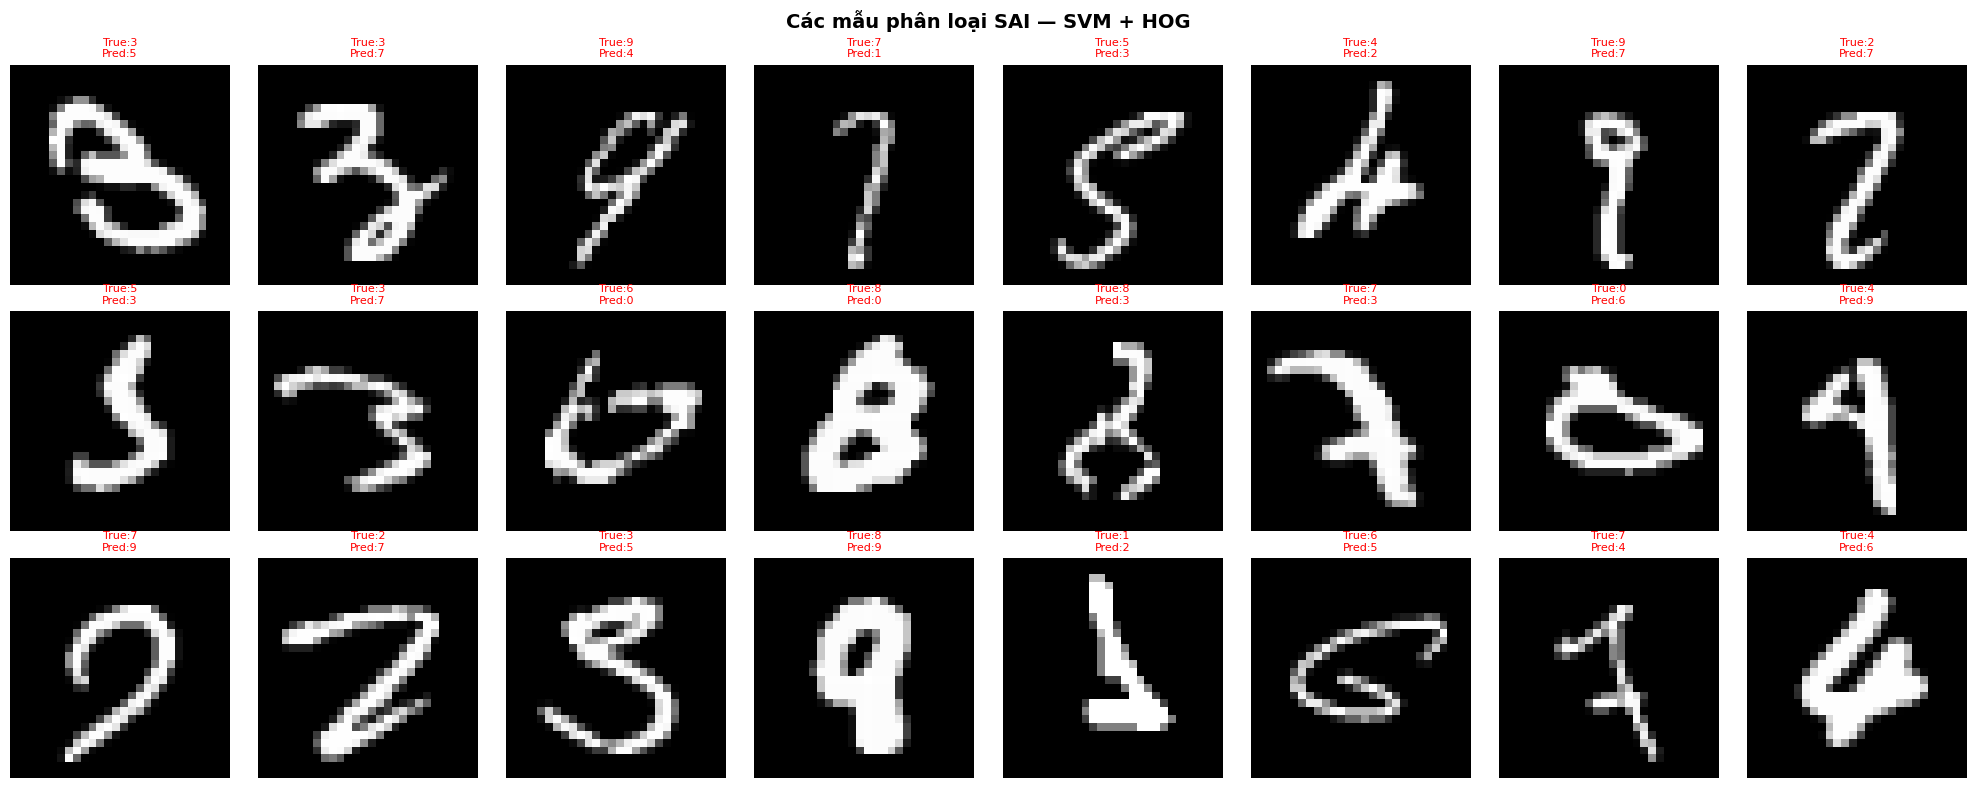

In [21]:
fig, axes = plt.subplots(3, 8, figsize=(20, 8))
fig.suptitle('Các mẫu phân loại SAI — SVM + HOG', fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    if i < len(wrong_indices):
        idx = wrong_indices[i]
        img = X_test_raw[idx].reshape(28, 28)
        ax.imshow(img, cmap='gray')
        ax.set_title(f'True:{y_test[idx]}\nPred:{y_pred[idx]}',
                    fontsize=8, color='red')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 8. So sánh các tham số SVM (Kernel comparison)

In [22]:
# So sánh nhanh với subset nhỏ hơn
SAMPLE_SIZE = 5000
np.random.seed(42)
idx_sample = np.random.choice(len(X_train_hog), SAMPLE_SIZE, replace=False)
X_sample = X_train_hog[idx_sample]
y_sample = y_train[idx_sample]

# Scale
scaler = StandardScaler()
X_sample_scaled = scaler.fit_transform(X_sample)
X_test_scaled = scaler.transform(X_test_hog)

kernels = ['linear', 'rbf', 'poly']
kernel_results = {}

print(f'So sánh kernel SVM trên {SAMPLE_SIZE:,} mẫu train...')
for kernel in kernels:
    t0 = time.time()
    clf = SVC(kernel=kernel, C=10, gamma='scale', random_state=42)
    clf.fit(X_sample_scaled, y_sample)
    y_pred_k = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_k)
    elapsed = time.time() - t0
    kernel_results[kernel] = {'accuracy': acc, 'time': elapsed}
    print(f'  {kernel:8s}: Accuracy={acc*100:.2f}%, Time={elapsed:.1f}s')

So sánh kernel SVM trên 5,000 mẫu train...
  linear  : Accuracy=96.97%, Time=11.0s
  rbf     : Accuracy=96.59%, Time=25.4s
  poly    : Accuracy=96.71%, Time=33.0s


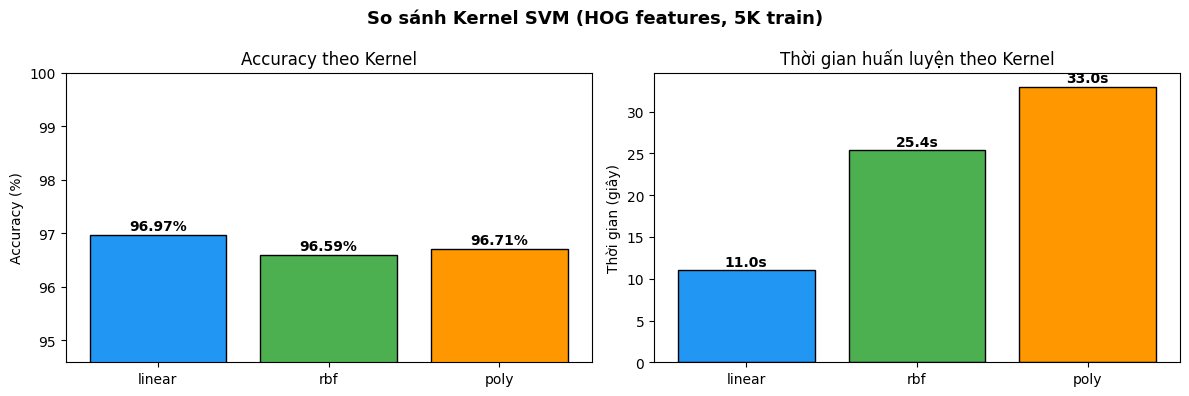

In [23]:
# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('So sánh Kernel SVM (HOG features, 5K train)', fontsize=13, fontweight='bold')

accs = [kernel_results[k]['accuracy']*100 for k in kernels]
times = [kernel_results[k]['time'] for k in kernels]
colors = ['#2196F3', '#4CAF50', '#FF9800']

axes[0].bar(kernels, accs, color=colors, edgecolor='black')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Accuracy theo Kernel')
for i, (k, a) in enumerate(zip(kernels, accs)):
    axes[0].text(i, a + 0.1, f'{a:.2f}%', ha='center', fontweight='bold')
axes[0].set_ylim([min(accs)-2, 100])

axes[1].bar(kernels, times, color=colors, edgecolor='black')
axes[1].set_ylabel('Thời gian (giây)')
axes[1].set_title('Thời gian huấn luyện theo Kernel')
for i, (k, t) in enumerate(zip(kernels, times)):
    axes[1].text(i, t + 0.5, f'{t:.1f}s', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 10. Kết luận

In [24]:
print('='*60)
print('TỔNG KẾT - SVM + HOG trên MNIST')
print('='*60)
print(f'''
🔧 Cấu hình:
   • Dataset   : MNIST (60K train / 10K test)
   • HOG params: orientations=8, pixels_per_cell=(4,4),
                 cells_per_block=(2,2), norm=L2-Hys
   • SVM kernel: RBF, C=10, gamma='scale'

📈 Kết quả:
   • Accuracy  : {accuracy*100:.2f}%
   • Sai       : {len(wrong_indices)}/10,000 mẫu
   • Train time: {train_time:.1f}s

💡 Nhận xét:
   • HOG bắt được cạnh và hướng gradient của chữ số
   • SVM-RBF hoạt động tốt với HOG features
   • Accuracy ~98%+ là kết quả rất tốt cho phương pháp truyền thống
   • Dễ nhầm lẫn giữa 4-9, 3-5, 7-1
''')
print('='*60)

TỔNG KẾT - SVM + HOG trên MNIST

🔧 Cấu hình:
   • Dataset   : MNIST (60K train / 10K test)
   • HOG params: orientations=8, pixels_per_cell=(4,4),
                 cells_per_block=(2,2), norm=L2-Hys
   • SVM kernel: RBF, C=10, gamma='scale'

📈 Kết quả:
   • Accuracy  : 98.28%
   • Sai       : 172/10,000 mẫu
   • Train time: 331.3s

💡 Nhận xét:
   • HOG bắt được cạnh và hướng gradient của chữ số
   • SVM-RBF hoạt động tốt với HOG features
   • Accuracy ~98%+ là kết quả rất tốt cho phương pháp truyền thống
   • Dễ nhầm lẫn giữa 4-9, 3-5, 7-1



In [25]:
import joblib

In [26]:
joblib.dump(svm_pipeline, '../../data/models/svm/svm_hog_mnist.h5')

['../../data/models/svm/svm_hog_mnist.h5']